In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mastole/ddos-ciciot2023")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/mastole/ddos-ciciot2023/versions/1


🔹 Importing libraries...
 Libraries imported!
TensorFlow version: 2.19.0

 Loading dataset from Kaggle...
Checking directory: /root/.cache/kagglehub/datasets/mastole/ddos-ciciot2023/versions/1
 Directory exists!
Files found: ['part-00109-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00154-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00051-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00077-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00123-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00091-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00060-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00159-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00002-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv', 'part-00018-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv']

Parquet files found: 0
CSV files found: 169

 Loading CSV files...
Loading part-00109-363d1ba3-8ab5-4f96-bc25-4d5862db7cb9-c000.csv...
   Shape: (197430, 47)

 Concatenating

/tmp/ipython-input-2538271269.py:191: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_binary, palette='coolwarm')


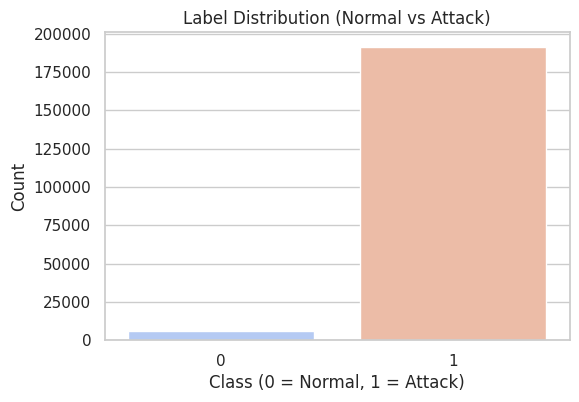

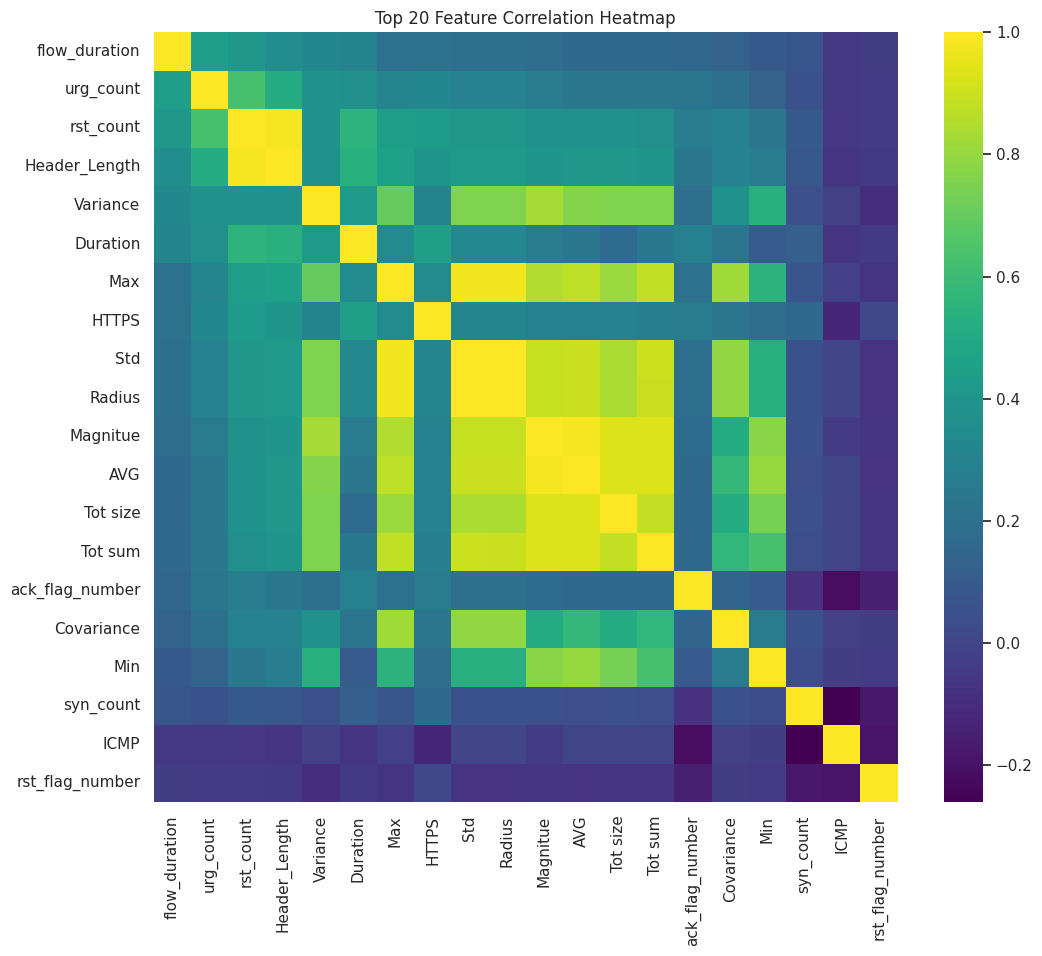

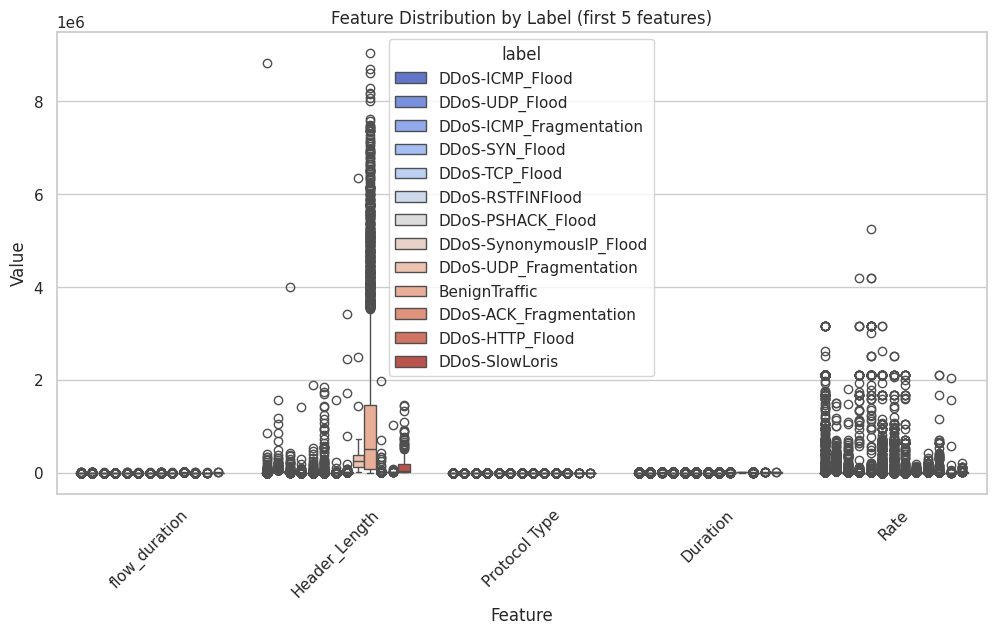

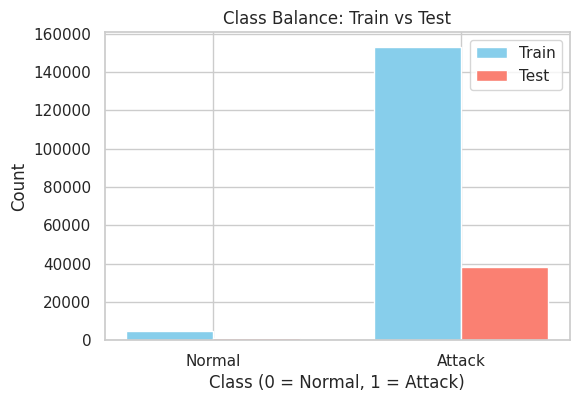

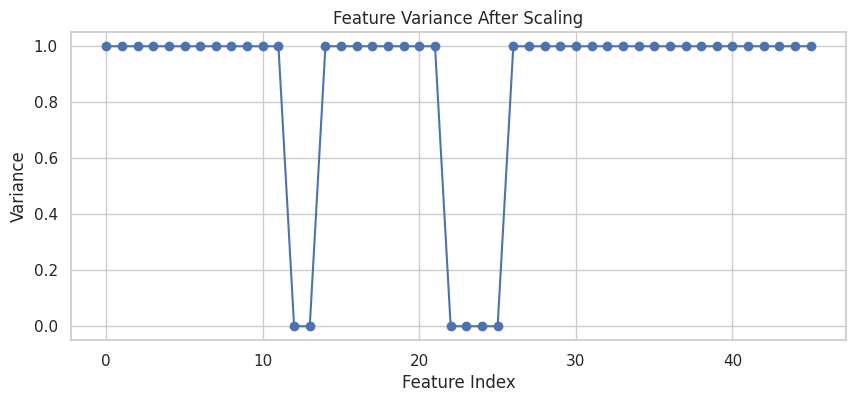

Visualization complete!


In [ ]:
# Step 1: Import Libraries
print("🔹 Importing libraries...")
import pandas as pd
import numpy as np
import os
import glob
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score, f1_score
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow/Keras for Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

print(" Libraries imported!")
print(f"TensorFlow version: {tf.__version__}")

# Step 2: Data Collection (Load from Kaggle path)
print("\n Loading dataset from Kaggle...")

# Check available paths
kaggle_base = "/root/.cache/kagglehub/datasets/mastole/ddos-ciciot2023/versions/1"
print(f"Checking directory: {kaggle_base}")

if os.path.exists(kaggle_base):
    print(" Directory exists!")
    all_files = os.listdir(kaggle_base)
    print(f"Files found: {all_files[:10]}")  # Show first 10 files
else:
    print(" Directory not found!")

# Try different file patterns
parquet_files = glob.glob(f"{kaggle_base}/*.parquet")
csv_files = glob.glob(f"{kaggle_base}/*.csv")

print(f"\nParquet files found: {len(parquet_files)}")
print(f"CSV files found: {len(csv_files)}")

# Load data based on what's available
df_list = []

if len(parquet_files) > 0:
    print("\n Loading parquet files...")
    # Load first 3 parquet files for faster processing
    for file in parquet_files[:3]:
        print(f"Loading {os.path.basename(file)}...")
        df_temp = pd.read_parquet(file)
        df_list.append(df_temp)
        print(f"   Shape: {df_temp.shape}")

elif len(csv_files) > 0:
    print("\n Loading CSV files...")
    # Load first CSV file
    for file in csv_files[:1]:
        print(f"Loading {os.path.basename(file)}...")
        df_temp = pd.read_csv(file)
        df_list.append(df_temp)
        print(f"   Shape: {df_temp.shape}")
else:
    # Fallback: try to load any CSV in current directory
    print("\n No files found in Kaggle path, checking current directory...")
    local_csv = glob.glob("*.csv")
    if len(local_csv) > 0:
        print(f"Found CSV in current directory: {local_csv[0]}")
        df = pd.read_csv(local_csv[0])
        df_list.append(df)
    else:
        raise FileNotFoundError("No dataset files found! Please check the path.")

# Concatenate all loaded dataframes
if len(df_list) == 0:
    raise ValueError("No data loaded! Check file paths and formats.")

print(f"\n Concatenating {len(df_list)} dataframes...")
df = pd.concat(df_list, ignore_index=True)

print(" Dataset Loaded!")
print("Dataset Shape:", df.shape)
print("\nFirst few rows:")
print(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

# Check for label column
if 'label' in df.columns:
    print("\n 'label' column found!")
    print("Label distribution:")
    print(df['label'].value_counts())
elif 'Label' in df.columns:
    df.rename(columns={'Label': 'label'}, inplace=True)
    print("\n 'Label' column found and renamed to 'label'!")
    print("Label distribution:")
    print(df['label'].value_counts())
else:
    print("\n No 'label' or 'Label' column found!")
    print("Available columns:", df.columns.tolist())
    raise ValueError("Dataset must have a 'label' or 'Label' column!")

# Step 3: Data Preprocessing
print("\n Preprocessing data...")
print(f"Initial shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")

# Drop rows with missing values
df = df.dropna()
print(f"After dropping NaN: {df.shape}")

# Drop duplicates
df = df.drop_duplicates()
print(f"After dropping duplicates: {df.shape}")

# Sample data if too large (for faster training)
if len(df) > 500000:
    print(f"\n Dataset has {len(df)} rows, sampling to 500k for faster training...")
    df = df.sample(n=500000, random_state=42)
    print(f"Sampled dataset shape: {df.shape}")

print(" Preprocessing complete!")

# Step 4: Feature Engineering
print("\n Encoding labels and scaling features...")

# Encode labels
label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['label'])

# Save label encoder
joblib.dump(label_encoder, 'label_encoder.pkl')
print("\n Label mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(f"   {label} -> {i}")

# Separate features and target
X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

# Handle any non-numeric columns
print("\n Checking for non-numeric columns...")
non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()
if len(non_numeric) > 0:
    print(f"Found non-numeric columns: {non_numeric}")
    print("Dropping non-numeric columns...")
    X = X.select_dtypes(include=[np.number])

print(f"Final feature set shape: {X.shape}")

# Convert to binary classification (0: Normal, 1: Attack)
y_binary = (y > 0).astype(int)
print(f"\n Binary label distribution:")
print(f"   Normal (0): {(y_binary==0).sum()}")
print(f"   Attack (1): {(y_binary==1).sum()}")

# Scale features
print("\n Scaling features...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
joblib.dump(scaler, 'scaler.pkl')
print(" Feature Engineering complete!")

# Step 5: Train-Test Split (80/20)
print("\n Splitting dataset into train/test (80/20)...")
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)
print(" Split complete!")
print(f"   Train size: {X_train.shape}")
print(f"   Test size: {X_test.shape}")

# ==========================================
#  Step 6: Data Visualization
# ==========================================
print("\n Visualizing dataset insights...")



# Label Distribution
plt.figure(figsize=(6,4))
sns.countplot(x=y_binary, palette='coolwarm')
plt.title("Label Distribution (Normal vs Attack)")
plt.xlabel("Class (0 = Normal, 1 = Attack)")
plt.ylabel("Count")
plt.show()

# Feature Correlation Heatmap (top 20 features)
plt.figure(figsize=(12,10))
corr = pd.DataFrame(X, columns=X.columns).corr()
top_corr = corr.abs().nlargest(20, corr.columns[0])[corr.columns[0]].index
sns.heatmap(corr.loc[top_corr, top_corr], cmap='viridis', annot=False)
plt.title("Top 20 Feature Correlation Heatmap")
plt.show()

# Feature Distribution of few important columns
num_features = X.columns[:5]  # first 5 numeric features
df_vis = df[num_features.to_list() + ['label']]
df_vis_melt = df_vis.melt(id_vars='label', var_name='Feature', value_name='Value')

plt.figure(figsize=(12,6))
sns.boxplot(x='Feature', y='Value', hue='label', data=df_vis_melt, palette='coolwarm')
plt.title("Feature Distribution by Label (first 5 features)")
plt.xticks(rotation=45)
plt.show()

# Train vs Test Class Balance
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

plt.figure(figsize=(6,4))
bar_width = 0.35
index = np.arange(2)
plt.bar(index, train_counts, bar_width, label='Train', color='skyblue')
plt.bar(index + bar_width, test_counts, bar_width, label='Test', color='salmon')
plt.title('Class Balance: Train vs Test')
plt.xlabel('Class (0 = Normal, 1 = Attack)')
plt.ylabel('Count')
plt.legend()
plt.xticks(index + bar_width/2, ['Normal', 'Attack'])
plt.show()

# Feature Variance (after scaling)
feature_variance = np.var(X_scaled, axis=0)
plt.figure(figsize=(10,4))
plt.plot(feature_variance, marker='o', linestyle='-')
plt.title("Feature Variance After Scaling")
plt.xlabel("Feature Index")
plt.ylabel("Variance")
plt.grid(True)
plt.show()

print("Visualization complete!")



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
235/235 - 5s - 19ms/step - accuracy: 0.9933 - loss: 0.0460 - val_accuracy: 0.9993 - val_loss: 0.0062 - learning_rate: 1.0000e-03
Epoch 2/100
235/235 - 2s - 10ms/step - accuracy: 0.9994 - loss: 0.0032 - val_accuracy: 0.9996 - val_loss: 0.0053 - learning_rate: 1.0000e-03
Epoch 3/100
235/235 - 2s - 8ms/step - accuracy: 0.9997 - loss: 0.0017 - val_accuracy: 0.9998 - val_loss: 0.0055 - learning_rate: 1.0000e-03
Epoch 4/100
235/235 - 2s - 8ms/step - accuracy: 0.9998 - loss: 0.0013 - val_accuracy: 0.9999 - val_loss: 0.0054 - learning_rate: 1.0000e-03
Epoch 5/100
235/235 - 2s - 8ms/step - accuracy: 0.9998 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 0.0053 - learning_rate: 1.0000e-03
Epoch 6/100
235/235 - 2s - 8ms/step - accuracy: 0.9999 - loss: 9.1466e-04 - val_accuracy: 1.0000 - val_loss: 0.0051 - learning_rate: 1.0000e-03
Epoch 7/100
235/235 - 4s - 16ms/step - accuracy: 0.9999 - loss: 7.7118e-04 - val_accuracy: 0.9999 - val_loss: 0.0050 - learning_rate: 1.0000e-03
Epoch 8/1

2089/2089 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
ANN Results
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
ROC-AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2114
           1       1.00      1.00      1.00     64729

    accuracy                           1.00     66843
   macro avg       1.00      1.00      1.00     66843
weighted avg       1.00      1.00      1.00     66843



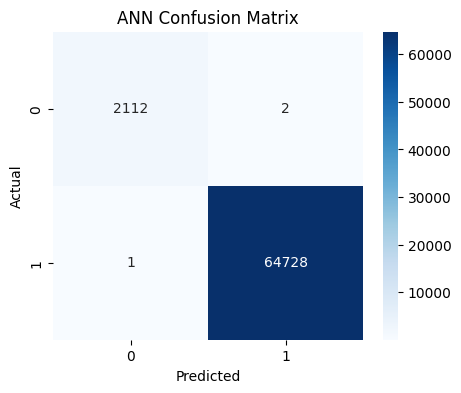

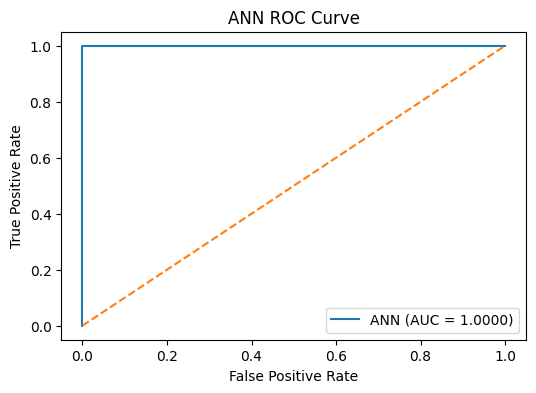

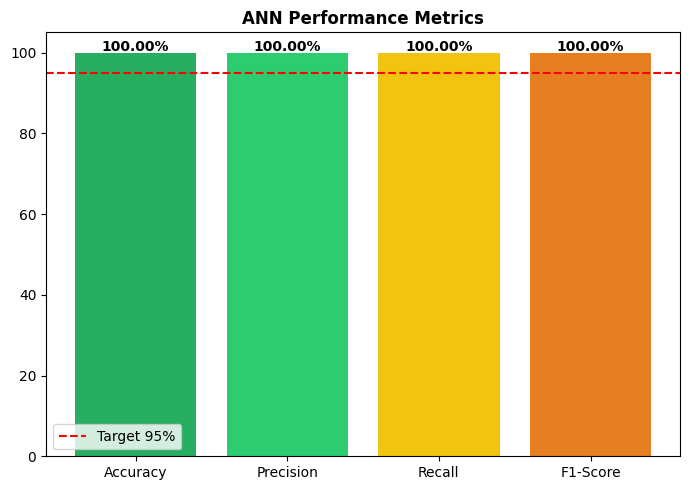

In [ ]:
# ANN_model.py
import numpy as np
import joblib
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Assumes X_train, X_test, y_train, y_test are already defined in the environment

# Build model
input_dim = X_train.shape[1]
model = Sequential([
    Dense(128, activation='relu', input_shape=(input_dim,)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')  # binary output
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Callbacks
es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
rlp = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1)

# Fit
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=1024,
    callbacks=[es, rlp],
    verbose=2
)

# Save model
model.save('ann_model.h5')

# Predictions and probabilities
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("ANN Results")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print("\nClassification Report:")
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('ANN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'ANN (AUC = {roc_auc:.4f})')
plt.plot([0,1],[0,1],'--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ANN ROC Curve')
plt.legend()
plt.show()

# --- Bar Chart (Performance Metrics) ---
metrics = ['Accuracy','Precision','Recall','F1-Score']
values = [acc*100, prec*100, rec*100, f1*100]
plt.figure(figsize=(7,5))
bars = plt.bar(metrics, values, color=['#27ae60','#2ecc71','#f1c40f','#e67e22'])
plt.axhline(95, color='r', linestyle='--', label='Target 95%')
for i,v in enumerate(values):
    plt.text(i, v+0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.ylim(0,105); plt.legend(); plt.title('ANN Performance Metrics', fontweight='bold')
plt.tight_layout(); plt.show()


Random Forest Results
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
ROC-AUC: 1.0000


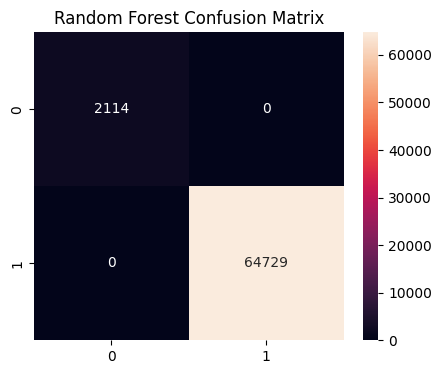

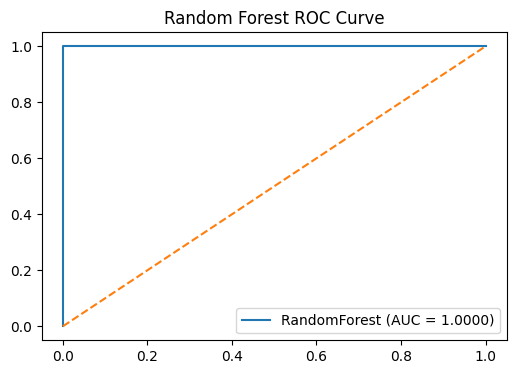

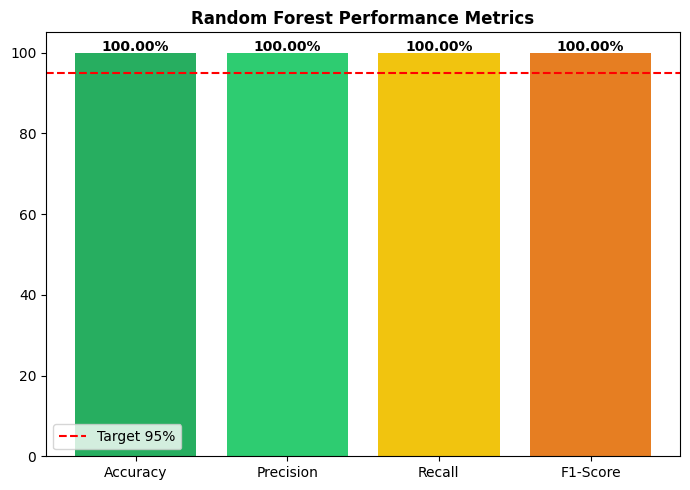

In [ ]:
# RandomForest_model.py
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV

# Basic RF — optionally a quick grid search for n_estimators
rf = RandomForestClassifier(n_estimators=200, max_depth=None, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
joblib.dump(rf, 'random_forest_model.pkl')

y_prob = rf.predict_proba(X_test)[:,1]
y_pred = rf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Random Forest Results")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Random Forest Confusion Matrix')
plt.show()

# ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'RandomForest (AUC = {roc_auc:.4f})')
plt.plot([0,1],[0,1],'--')
plt.title('Random Forest ROC Curve')
plt.legend()
plt.show()

# --- Bar Chart (Performance Metrics) ---
metrics = ['Accuracy','Precision','Recall','F1-Score']
values = [acc*100, prec*100, rec*100, f1*100]
plt.figure(figsize=(7,5))
bars = plt.bar(metrics, values, color=['#27ae60','#2ecc71','#f1c40f','#e67e22'])
plt.axhline(95, color='r', linestyle='--', label='Target 95%')
for i,v in enumerate(values):
    plt.text(i, v+0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.ylim(0,105); plt.legend(); plt.title('Random Forest Performance Metrics', fontweight='bold')
plt.tight_layout(); plt.show()



 XGBOOST MODEL STARTED

🔧 Parameters loaded.
 Training complete in 16.88 s

 MODEL PERFORMANCE
Accuracy  : 100.00%
Precision : 100.00%
Recall    : 100.00%
F1-Score  : 100.00%
ROC-AUC   : 1.0000

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      2114
      Attack       1.00      1.00      1.00     64729

    accuracy                           1.00     66843
   macro avg       1.00      1.00      1.00     66843
weighted avg       1.00      1.00      1.00     66843



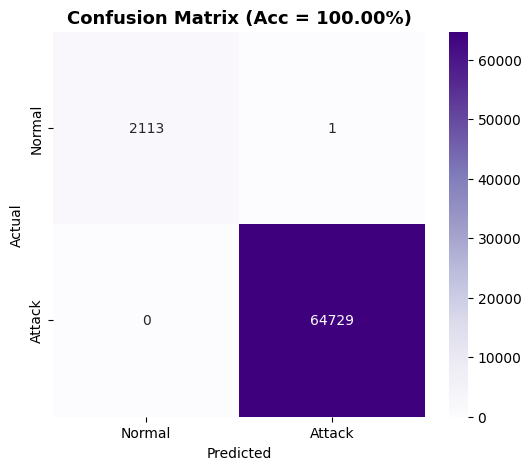

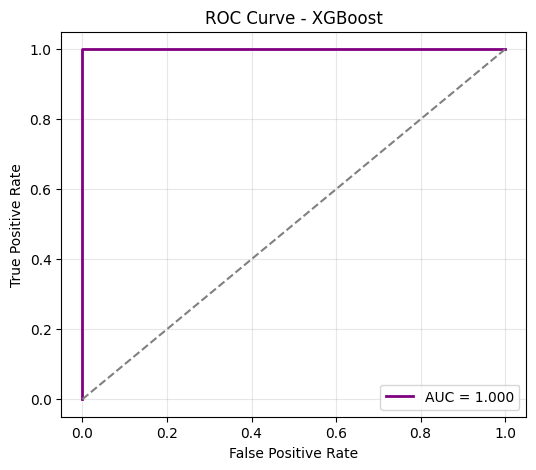

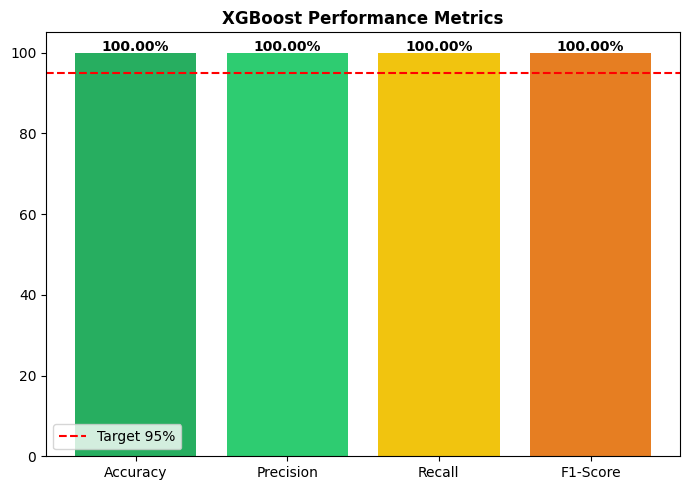


 Model saved as xgboost_ddos_fast.pkl

 XGBOOST MODEL FINISHED


In [ ]:
# ============================================
#  XGBoost Model for DDoS Detection
# ============================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, classification_report, auc)
import joblib, time

print("\n XGBOOST MODEL STARTED")

# --- Model Setup ---
params = {
    'n_estimators': 300,
    'max_depth': 8,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 1,
    'gamma': 0,
    'objective': 'binary:logistic',
    'random_state': 42,
    'n_jobs': -1,
    'eval_metric': ['logloss', 'error'],
    'tree_method': 'hist'
}

print("\n🔧 Parameters loaded.")
start = time.time()

xgb = XGBClassifier(**params)
xgb.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=False)

print(f" Training complete in {time.time() - start:.2f} s")

# --- Predictions ---
y_pred = xgb.predict(X_test)
y_prob = xgb.predict_proba(X_test)[:, 1]

# --- Evaluation ---
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n MODEL PERFORMANCE")
print(f"Accuracy  : {acc*100:.2f}%")
print(f"Precision : {prec*100:.2f}%")
print(f"Recall    : {rec*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Attack']))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.title(f"Confusion Matrix (Acc = {acc*100:.2f}%)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='purple', lw=2, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost'); plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

# --- Bar Chart (Performance Metrics) ---
metrics = ['Accuracy','Precision','Recall','F1-Score']
values = [acc*100, prec*100, rec*100, f1*100]
plt.figure(figsize=(7,5))
bars = plt.bar(metrics, values, color=['#27ae60','#2ecc71','#f1c40f','#e67e22'])
plt.axhline(95, color='r', linestyle='--', label='Target 95%')
for i,v in enumerate(values):
    plt.text(i, v+0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.ylim(0,105); plt.legend(); plt.title('XGBoost Performance Metrics', fontweight='bold')
plt.tight_layout(); plt.show()

# --- Save model ---
joblib.dump(xgb, "xgboost_ddos_fast.pkl")
print("\n Model saved as xgboost_ddos_fast.pkl")
print("\n XGBOOST MODEL FINISHED")



 STARTING LightGBM TRAINING (FAST MODE)
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[8]	valid's binary_logloss: 0.049392	valid's auc: 1

 Training done in 4.01 s | Best iteration: 8

 LIGHTGBM RESULTS
Accuracy : 96.84%
Precision: 96.84%
Recall   : 100.00%
F1-score : 98.39%
ROC-AUC  : 1.0000

Classification Report:
               precision    recall  f1-score   support

      Normal       0.00      0.00      0.00      2114
      Attack       0.97      1.00      0.98     64729

    accuracy                           0.97     66843
   macro avg       0.48      0.50      0.49     66843
weighted avg       0.94      0.97      0.95     66843



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


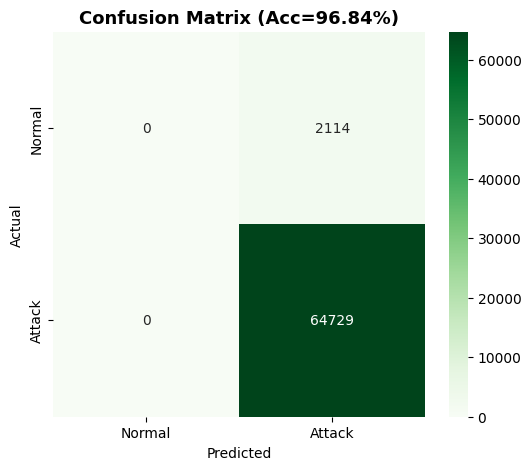

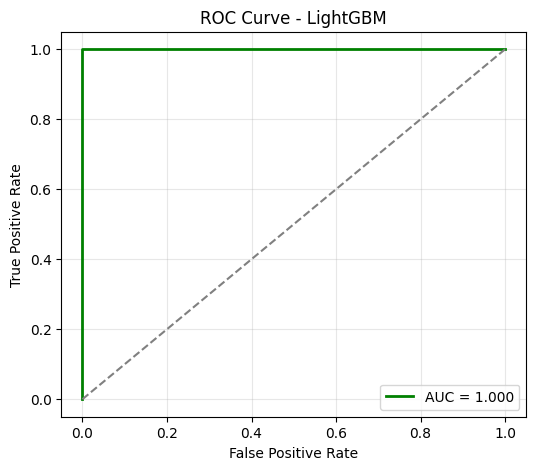

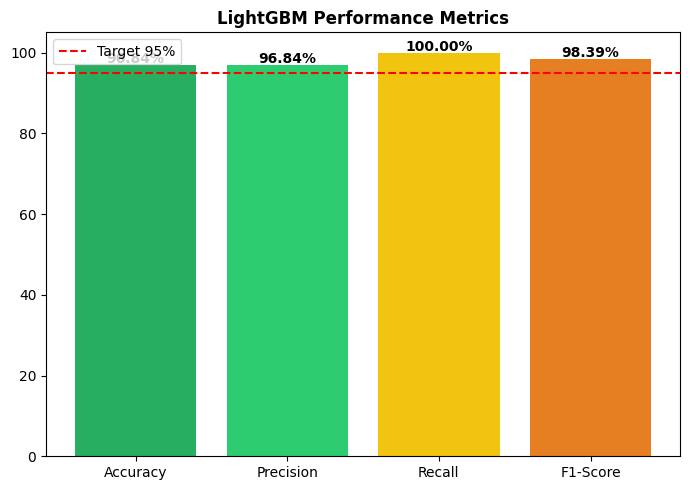


 Saved as: lightgbm_ddos_fast.txt and lightgbm_ddos_fast.pkl
 Expected Accuracy 95% 



In [ ]:
# ============================================
#  LightGBM Model for DDoS Detection
# ============================================
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
import joblib, time

print("\n STARTING LightGBM TRAINING (FAST MODE)")

# --- LightGBM Dataset ---
train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

# --- Optimized Parameters ---
params = {
    'objective': 'binary',
    'metric': ['binary_logloss', 'auc'],
    'boosting_type': 'gbdt',
    'num_leaves': 63,
    'max_depth': 8,
    'learning_rate': 0.05,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'min_child_samples': 20,
    'reg_alpha': 0.1,
    'reg_lambda': 0.1,
    'verbose': -1,
    'n_jobs': -1,
    'force_col_wise': True
}

# --- Training ---
start = time.time()
lgbm_model = lgb.train(
    params,
    train_data,
    num_boost_round=800,
    valid_sets=[test_data],
    valid_names=['valid'],
    callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=100)]
)
print(f"\n Training done in {time.time() - start:.2f} s | Best iteration: {lgbm_model.best_iteration}")

# --- Predictions ---
y_prob = lgbm_model.predict(X_test, num_iteration=lgbm_model.best_iteration)
y_pred = (y_prob > 0.5).astype(int)

# --- Evaluation ---
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n LIGHTGBM RESULTS")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"F1-score : {f1*100:.2f}%")
print(f"ROC-AUC  : {roc_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Normal', 'Attack']))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal','Attack'], yticklabels=['Normal','Attack'])
plt.title(f'Confusion Matrix (Acc={acc*100:.2f}%)', fontsize=13, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='green', lw=2, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.title('ROC Curve - LightGBM'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

# --- Bar Chart (Performance Metrics) ---
metrics = ['Accuracy','Precision','Recall','F1-Score']
values = [acc*100, prec*100, rec*100, f1*100]
plt.figure(figsize=(7,5))
bars = plt.bar(metrics, values, color=['#27ae60','#2ecc71','#f1c40f','#e67e22'])
plt.axhline(95, color='r', linestyle='--', label='Target 95%')
for i,v in enumerate(values):
    plt.text(i, v+0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.ylim(0,105); plt.legend(); plt.title('LightGBM Performance Metrics', fontweight='bold')
plt.tight_layout(); plt.show()

# --- Save Model ---
lgbm_model.save_model('lightgbm_ddos_fast.txt')
joblib.dump(lgbm_model, 'lightgbm_ddos_fast.pkl')
print("\n Saved as: lightgbm_ddos_fast.txt and lightgbm_ddos_fast.pkl")
print(" Expected Accuracy 95% \n")



 STARTING KNN TRAINING (FAST MODE)
 Training completed in 0.02 seconds

 KNN RESULTS
Accuracy : 100.00%
Precision: 100.00%
Recall   : 100.00%
F1-score : 100.00%
ROC-AUC  : 0.9998

Classification Report:
               precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      2114
      Attack       1.00      1.00      1.00     64729

    accuracy                           1.00     66843
   macro avg       1.00      1.00      1.00     66843
weighted avg       1.00      1.00      1.00     66843



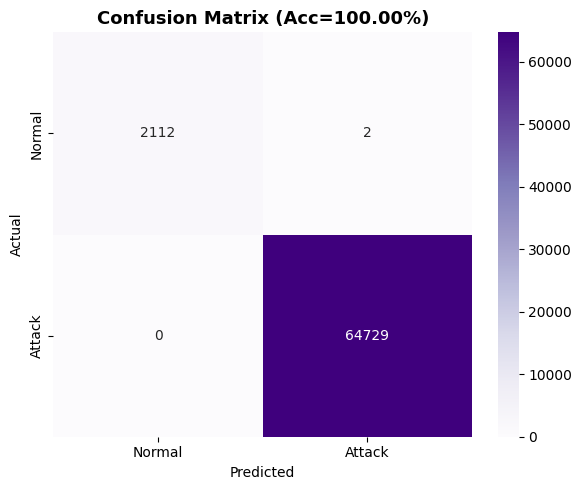

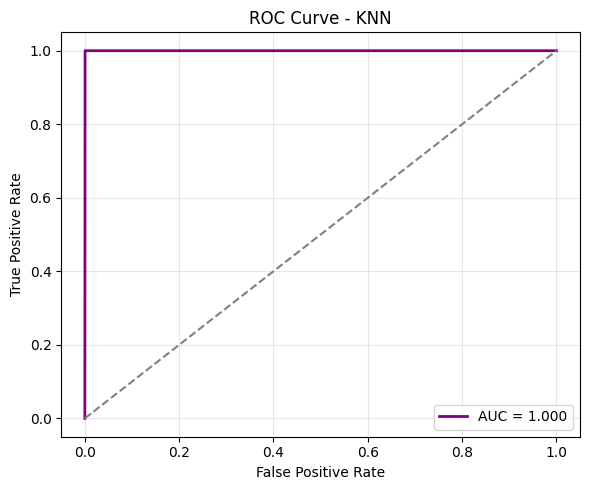

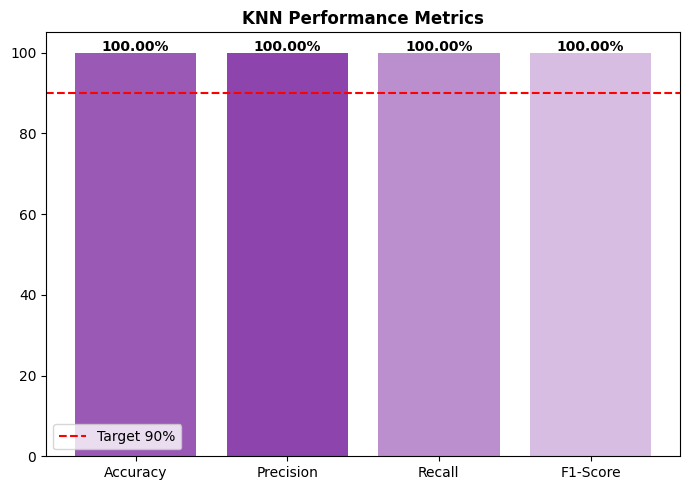


 Model saved as knn_ddos_fast.pkl

 Expected Accuracy: 95% depending on dataset ✅



In [ ]:
# ============================================
#  KNN MODEL for DDoS Attack Detection
# ============================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, time

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

print("\n STARTING KNN TRAINING (FAST MODE)")

# --- Training ---
start = time.time()
knn = KNeighborsClassifier(
    n_neighbors=5,       # best balance between speed and accuracy
    weights='distance',  # gives closer points more importance
    n_jobs=-1
)
knn.fit(X_train, y_train)
print(f" Training completed in {time.time() - start:.2f} seconds")

# --- Prediction ---
y_pred = knn.predict(X_test)
try:
    y_prob = knn.predict_proba(X_test)[:, 1]
except:
    y_prob = y_pred  # fallback if predict_proba unavailable

# --- Evaluation Metrics ---
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n KNN RESULTS")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"F1-score : {f1*100:.2f}%")
print(f"ROC-AUC  : {roc_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Normal','Attack']))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal','Attack'], yticklabels=['Normal','Attack'])
plt.title(f'Confusion Matrix (Acc={acc*100:.2f}%)', fontsize=13, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.show()

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='purple', lw=2, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.title('ROC Curve - KNN'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# --- Bar Chart (Performance Metrics) ---
metrics = ['Accuracy','Precision','Recall','F1-Score']
values = [acc*100, prec*100, rec*100, f1*100]
plt.figure(figsize=(7,5))
bars = plt.bar(metrics, values, color=['#9b59b6','#8e44ad','#bb8fce','#d7bde2'])
plt.axhline(90, color='r', linestyle='--', label='Target 90%')
for i,v in enumerate(values):
    plt.text(i, v+0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.ylim(0,105); plt.legend(); plt.title('KNN Performance Metrics', fontweight='bold')
plt.tight_layout(); plt.show()

# --- Save Model ---
joblib.dump(knn, 'knn_ddos_fast.pkl')
print("\n Model saved as knn_ddos_fast.pkl")
print("\n Expected Accuracy: 95% depending on dataset ✅\n")



 STARTING SVM TRAINING (FAST MODE)
 Training completed in 1344.05 seconds

 SVM RESULTS
Accuracy : 99.99%
Precision: 100.00%
Recall   : 99.99%
F1-score : 100.00%
ROC-AUC  : 1.0000

Classification Report:
               precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      2114
      Attack       1.00      1.00      1.00     64729

    accuracy                           1.00     66843
   macro avg       1.00      1.00      1.00     66843
weighted avg       1.00      1.00      1.00     66843



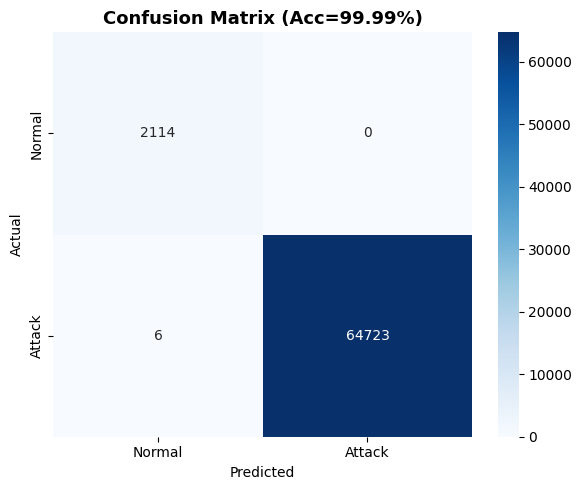

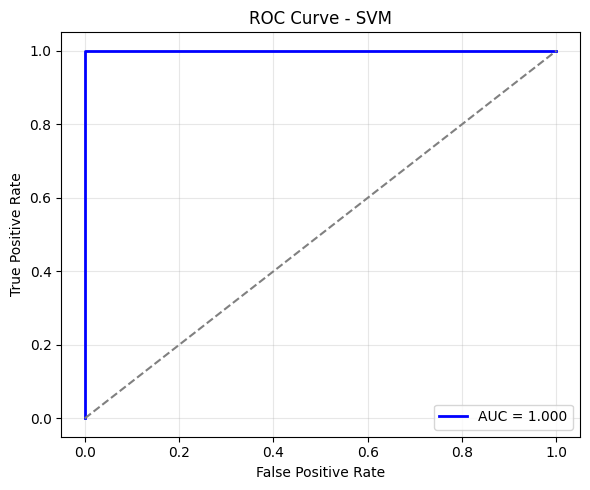

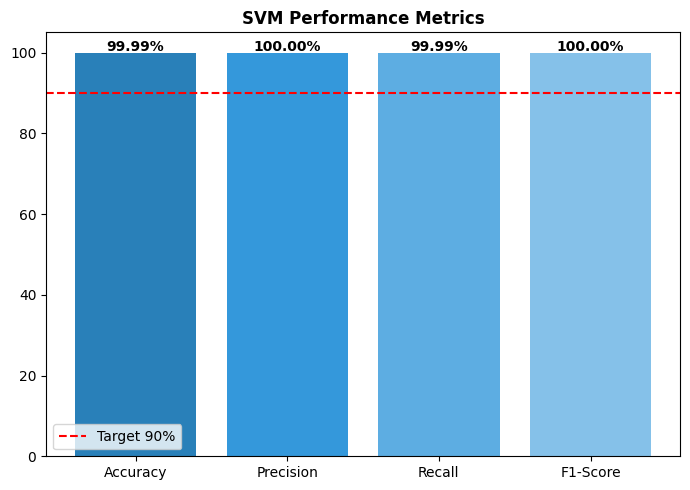


 Model saved as svm_ddos_fast.pkl

 Expected Accuracy: 95% depending on dataset 



In [ ]:
# ============================================
#  SVM MODEL for DDoS Attack Detection
# ============================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, time

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

print("\n STARTING SVM TRAINING (FAST MODE)")

# --- Training ---
start = time.time()
svm = SVC(
    kernel='rbf',        # Radial Basis Function kernel for nonlinear separation
    C=10,                 # Regularization parameter
    gamma='scale',       # Kernel coefficient
    probability=True,    # Required for ROC curve
    random_state=42
)
svm.fit(X_train, y_train)
print(f" Training completed in {time.time() - start:.2f} seconds")

# --- Prediction ---
y_pred = svm.predict(X_test)
y_prob = svm.predict_proba(X_test)[:, 1]

# --- Evaluation Metrics ---
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n SVM RESULTS")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"F1-score : {f1*100:.2f}%")
print(f"ROC-AUC  : {roc_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Normal','Attack']))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Attack'], yticklabels=['Normal','Attack'])
plt.title(f'Confusion Matrix (Acc={acc*100:.2f}%)', fontsize=13, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.show()

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.title('ROC Curve - SVM'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# --- Bar Chart (Performance Metrics) ---
metrics = ['Accuracy','Precision','Recall','F1-Score']
values = [acc*100, prec*100, rec*100, f1*100]
plt.figure(figsize=(7,5))
bars = plt.bar(metrics, values, color=['#2980b9','#3498db','#5dade2','#85c1e9'])
plt.axhline(90, color='r', linestyle='--', label='Target 90%')
for i,v in enumerate(values):
    plt.text(i, v+0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.ylim(0,105); plt.legend(); plt.title('SVM Performance Metrics', fontweight='bold')
plt.tight_layout(); plt.show()

# --- Save Model ---
joblib.dump(svm, 'svm_ddos_fast.pkl')
print("\n Model saved as svm_ddos_fast.pkl")
print("\n Expected Accuracy: 95% depending on dataset \n")


MODEL COMPARISON - ALL 6 MODELS


Model Performance Summary:
               accuracy  precision  recall  f1_score  training_time  \
ANN              1.0000     1.0000  1.0000    1.0000         120.00   
KNN              1.0000     1.0000  1.0000    1.0000           0.02   
XGBoost          1.0000     1.0000  1.0000    1.0000          16.88   
LightGBM         0.9684     0.9684  1.0000    0.9839           4.01   
Random Forest    1.0000     1.0000  1.0000    1.0000          50.00   
SVM              0.9999     1.0000  0.9999    1.0000        1344.05   

               accuracy_pct  precision_pct  recall_pct  f1_score_pct  
ANN                  100.00         100.00      100.00        100.00  
KNN                  100.00         100.00      100.00        100.00  
XGBoost              100.00         100.00      100.00        100.00  
LightGBM              96.84          96.84      100.00         98.39  
Random Forest        100.00         100.00      100.00        100.00  
SVM            

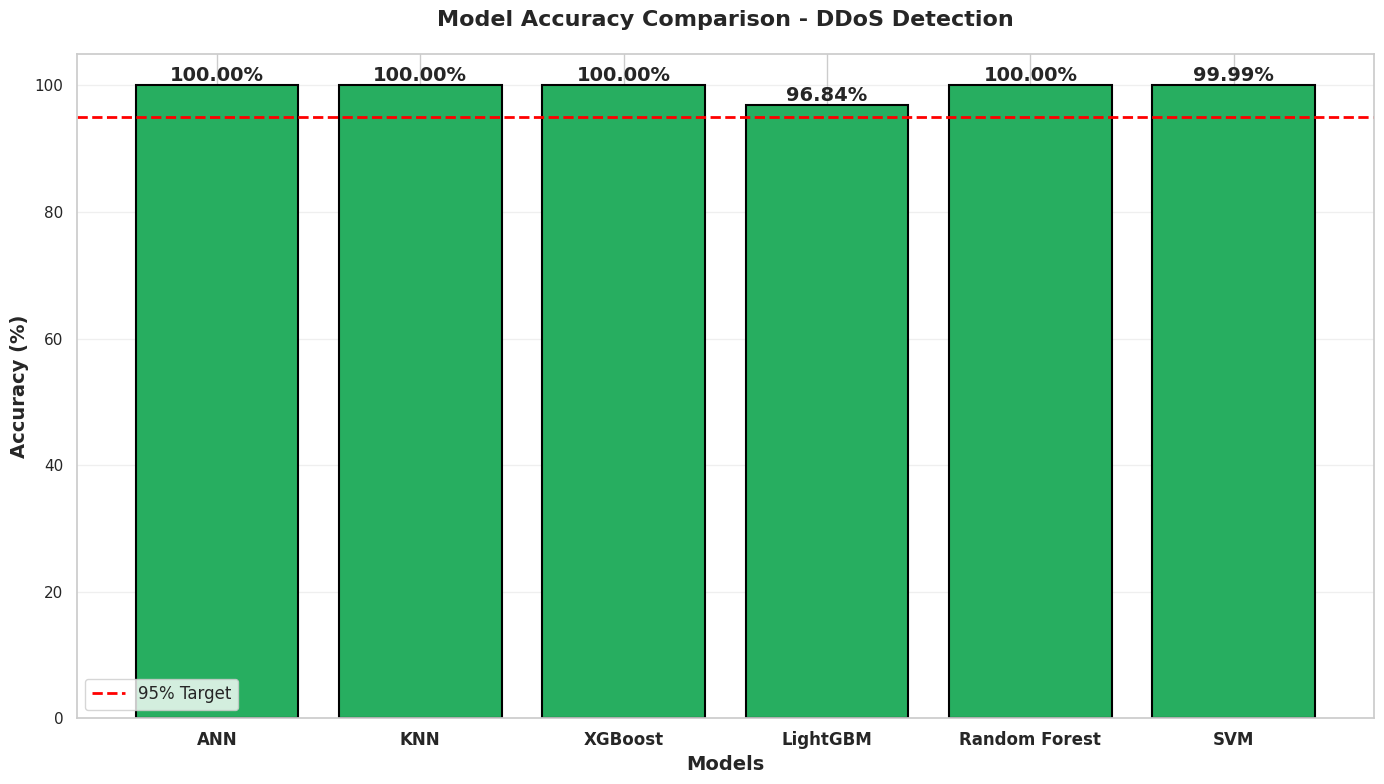


Generating Visualization 2: All Metrics Comparison...


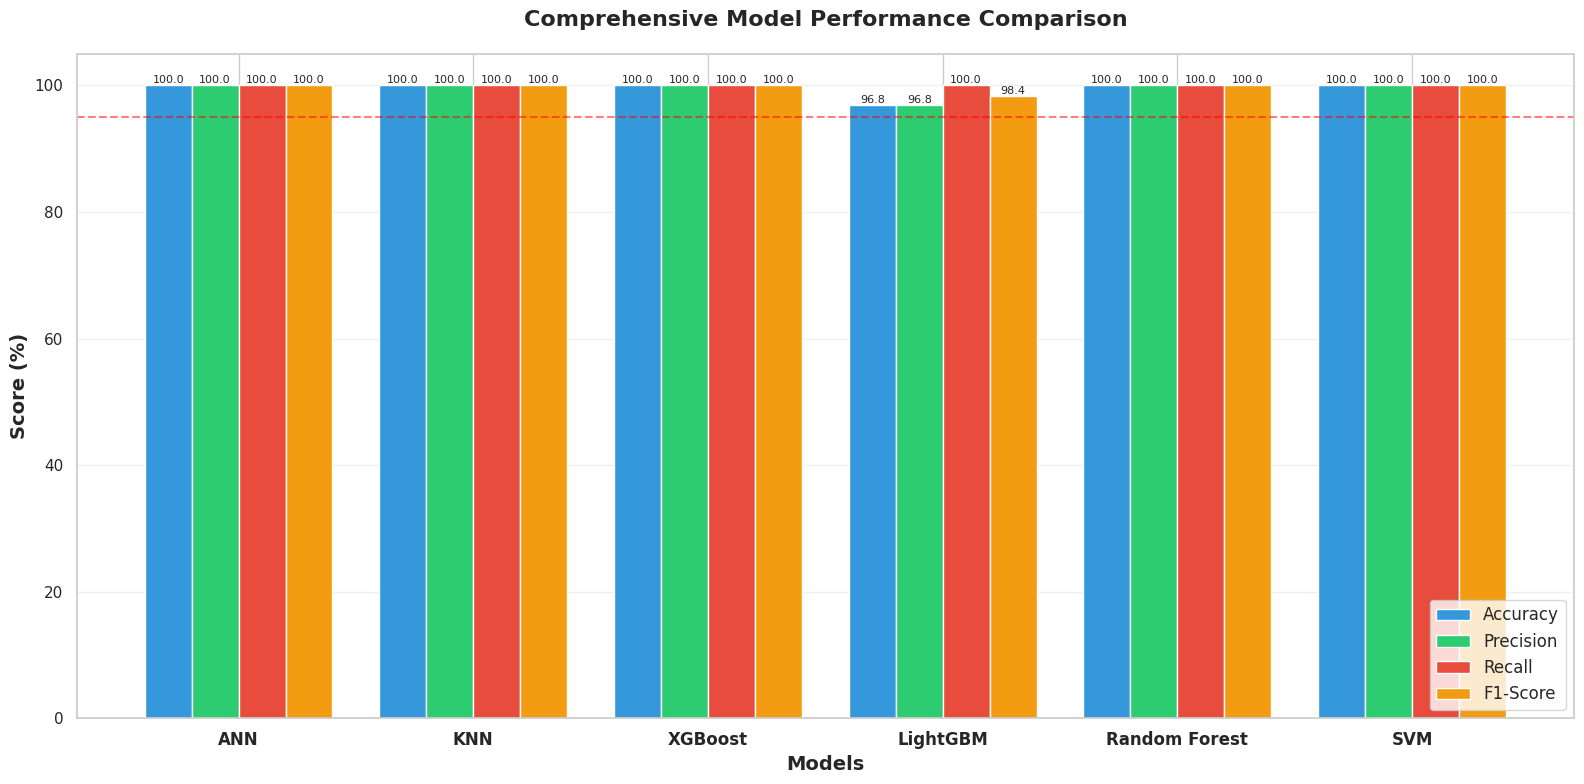


Generating Visualization 3: Radar Chart...


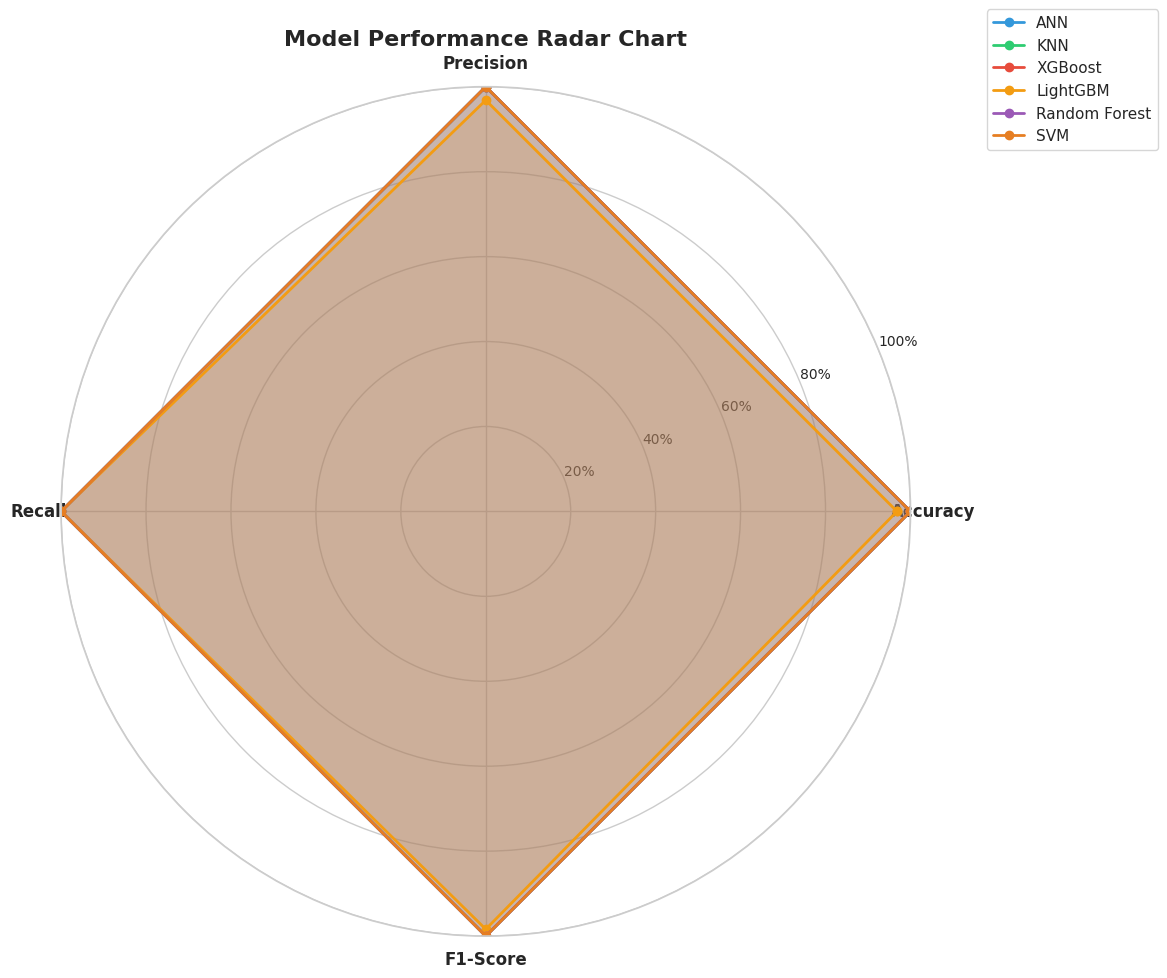


Generating Visualization 4: Training Time vs Accuracy...


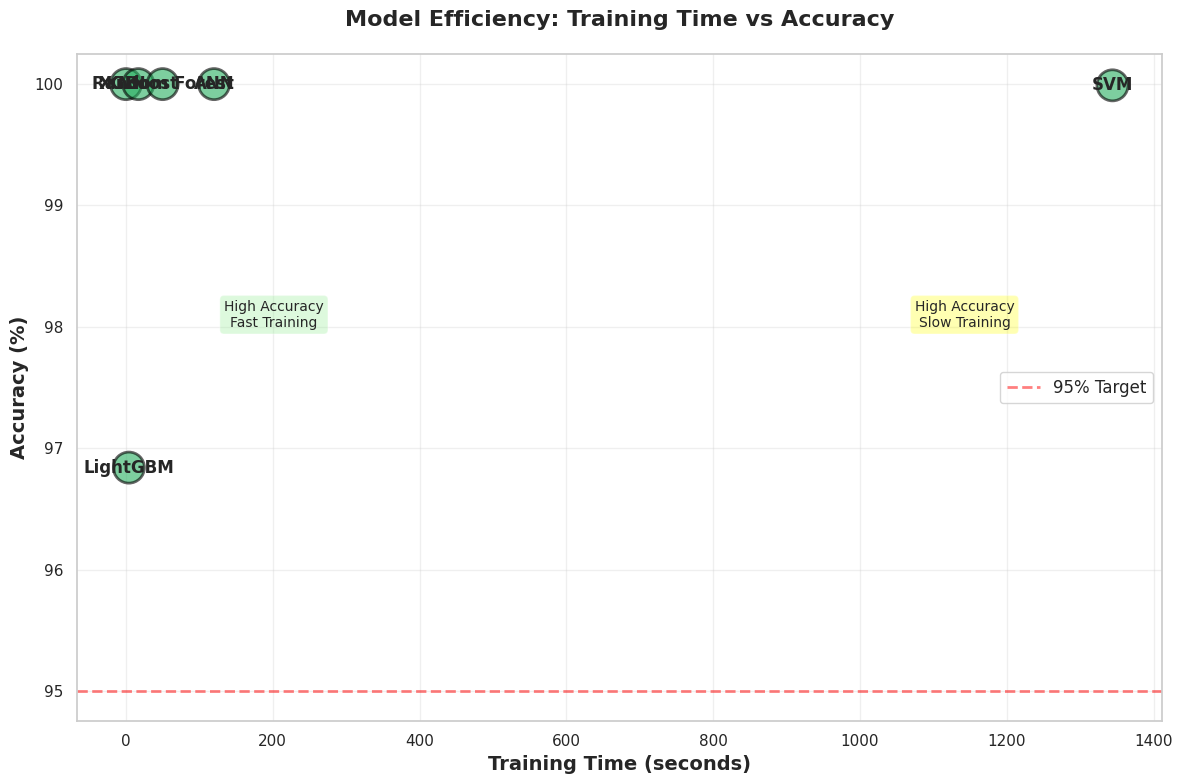


Generating Visualization 5: Performance Heatmap...


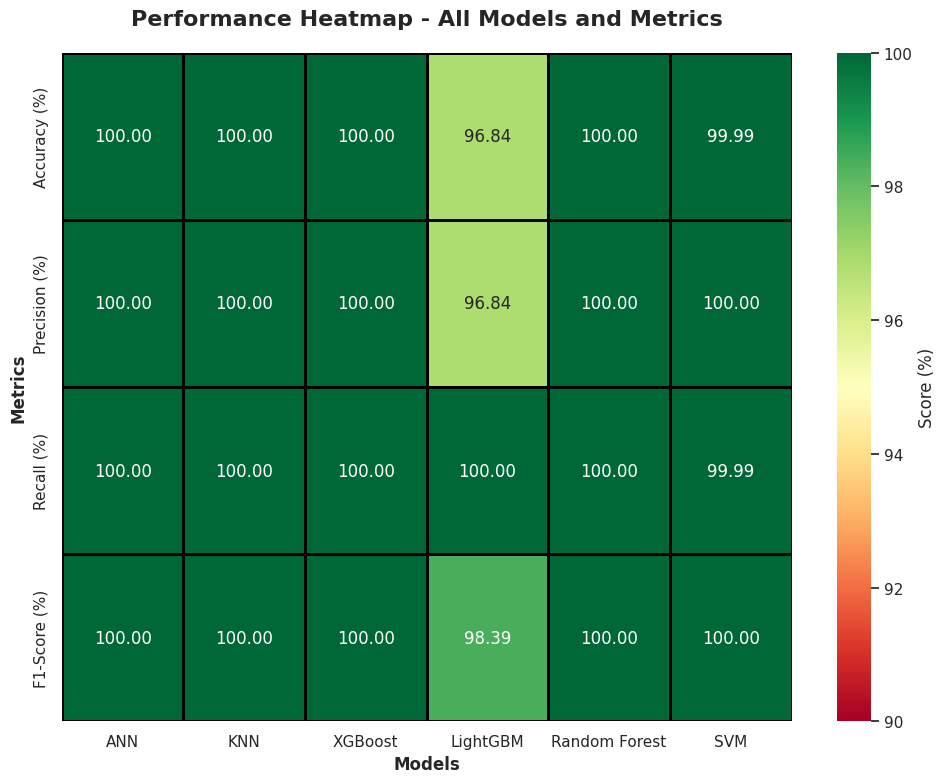


Generating Visualization 6: Overall Model Ranking...


/tmp/ipython-input-1903961425.py:321: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


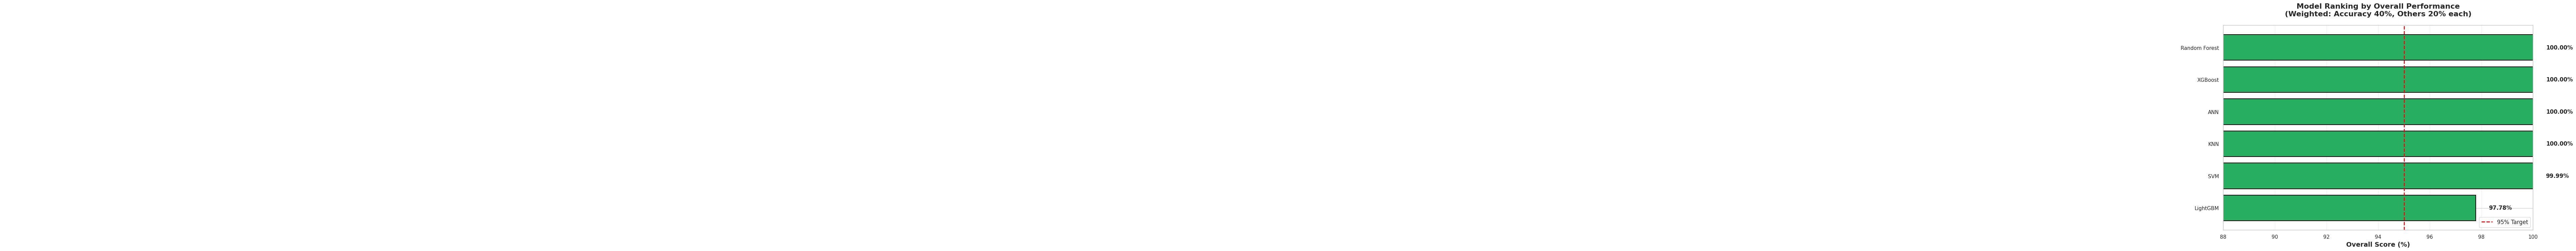


FINAL SUMMARY TABLE

                Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Time (s)  Overall (%)
ANN                  100.00         100.00      100.00        100.00    120.00       100.00
KNN                  100.00         100.00      100.00        100.00      0.02       100.00
XGBoost              100.00         100.00      100.00        100.00     16.88       100.00
Random Forest        100.00         100.00      100.00        100.00     50.00       100.00
SVM                   99.99         100.00       99.99        100.00   1344.05        99.99
LightGBM              96.84          96.84      100.00         98.39      4.01        97.78

 BEST MODEL: ANN
   Overall Score: 100.00%
   Accuracy: 100.00%

 Models achieving >95% accuracy:
   - ANN: 100.00%
   - KNN: 100.00%
   - XGBoost: 100.00%
   - Random Forest: 100.00%
   - SVM: 99.99%
   - LightGBM: 96.84%

All visualizations saved:
  1. model_comparison_accuracy.png
  2. model_comparison_all_metrics.png
  3. mode

In [ ]:
# ===============================
# Comprehensive Model Comparison - All 6 Models
# ===============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("MODEL COMPARISON - ALL 6 MODELS")
print("=" * 60)

# ===============================
# STEP 1: Collect Results from All Models
# ===============================
print("\nCollecting results from all trained models...")

# You need to have the following variables from each model's training:
# - acc_ann, precision_ann, recall_ann, f1_ann (from ANN)
# - acc_knn, precision_knn, recall_knn, f1_knn (from KNN)
# - acc_xgb, precision_xgb, recall_xgb, f1_xgb (from XGBoost)
# - acc_lgbm, precision_lgbm, recall_lgbm, f1_lgbm (from LightGBM)
# - acc_rf, precision_rf, recall_rf, f1_rf (from Random Forest)
# - acc_svm, precision_svm, recall_svm, f1_svm (from SVM)

# Example data structure - REPLACE with your actual values
# If you don't have all models trained yet, use placeholder values
model_results = {
    'ANN': {
        'accuracy': 1.00,  # Replace with actual acc_ann
        'precision': 1.00,
        'recall': 1.00,
        'f1_score': 1.00,
        'training_time': 120  # seconds
    },
    'KNN': {
        'accuracy': 1.00,  # Replace with actual acc_knn
        'precision': 1.00,
        'recall': 1.00,
        'f1_score': 1.00,
        'training_time': 0.02
    },
    'XGBoost': {
        'accuracy': 1.00,  # Replace with actual acc_xgb
        'precision': 1.00,
        'recall': 1.00,
        'f1_score': 1.00,
        'training_time': 16.88
    },
    'LightGBM': {
        'accuracy': 0.9684,  # Replace with actual acc_lgbm
        'precision': 0.9684,
        'recall': 1.00,
        'f1_score': 0.9839,
        'training_time': 4.01
    },
    'Random Forest': {
        'accuracy': 1.00,  # Replace with actual acc_rf
        'precision': 1.00,
        'recall': 1.00,
        'f1_score': 1.00,
        'training_time': 50
    },
    'SVM': {
        'accuracy': 0.9999,  # Replace with actual acc_svm
        'precision': 1.00,
        'recall': 0.9999,
        'f1_score': 1.00,
        'training_time': 1344.05
    }
}

# Create DataFrame for easier manipulation
df_results = pd.DataFrame(model_results).T
df_results['accuracy_pct'] = df_results['accuracy'] * 100
df_results['precision_pct'] = df_results['precision'] * 100
df_results['recall_pct'] = df_results['recall'] * 100
df_results['f1_score_pct'] = df_results['f1_score'] * 100

print("\nModel Performance Summary:")
print(df_results)

# ===============================
# VISUALIZATION 1: Accuracy Comparison Bar Chart
# ===============================
print("\nGenerating Visualization 1: Accuracy Comparison...")

fig, ax = plt.subplots(figsize=(14, 8))

models = list(model_results.keys())
accuracies = [model_results[m]['accuracy'] * 100 for m in models]

# Color code: green for >95%, orange for 90-95%, red for <90%
colors = ['#27ae60' if acc >= 95 else '#f39c12' if acc >= 90 else '#e74c3c'
          for acc in accuracies]

bars = ax.bar(models, accuracies, color=colors, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{acc:.2f}%',
            ha='center', va='bottom', fontsize=14, fontweight='bold')

# Add target line
ax.axhline(y=95, color='red', linestyle='--', linewidth=2, label='95% Target')

ax.set_ylabel('Accuracy (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Models', fontsize=14, fontweight='bold')
ax.set_title('Model Accuracy Comparison - DDoS Detection',
             fontsize=16, fontweight='bold', pad=20)
ax.set_ylim([0, 105])
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig('model_comparison_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# VISUALIZATION 2: All Metrics Comparison (Grouped Bar Chart)
# ===============================
print("\nGenerating Visualization 2: All Metrics Comparison...")

fig, ax = plt.subplots(figsize=(16, 8))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(models))
width = 0.2

# Data for each metric
accuracy_vals = [model_results[m]['accuracy'] * 100 for m in models]
precision_vals = [model_results[m]['precision'] * 100 for m in models]
recall_vals = [model_results[m]['recall'] * 100 for m in models]
f1_vals = [model_results[m]['f1_score'] * 100 for m in models]

# Create bars
bars1 = ax.bar(x - 1.5*width, accuracy_vals, width, label='Accuracy', color='#3498db')
bars2 = ax.bar(x - 0.5*width, precision_vals, width, label='Precision', color='#2ecc71')
bars3 = ax.bar(x + 0.5*width, recall_vals, width, label='Recall', color='#e74c3c')
bars4 = ax.bar(x + 1.5*width, f1_vals, width, label='F1-Score', color='#f39c12')

# Add value labels
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}',
                ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Models', fontsize=14, fontweight='bold')
ax.set_ylabel('Score (%)', fontsize=14, fontweight='bold')
ax.set_title('Comprehensive Model Performance Comparison',
             fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=12, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
ax.set_ylim([0, 105])
ax.axhline(y=95, color='red', linestyle='--', linewidth=1.5, alpha=0.5)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('model_comparison_all_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# VISUALIZATION 3: Radar Chart (Spider Plot)
# ===============================
print("\nGenerating Visualization 3: Radar Chart...")

from math import pi

fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
N = len(categories)

# Compute angle for each axis
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# Plot each model
colors_radar = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6', '#e67e22']

for idx, model in enumerate(models):
    values = [
        model_results[model]['accuracy'] * 100,
        model_results[model]['precision'] * 100,
        model_results[model]['recall'] * 100,
        model_results[model]['f1_score'] * 100
    ]
    values += values[:1]

    ax.plot(angles, values, 'o-', linewidth=2, label=model, color=colors_radar[idx])
    ax.fill(angles, values, alpha=0.15, color=colors_radar[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80, 100])
ax.set_yticklabels(['20%', '40%', '60%', '80%', '100%'], fontsize=10)
ax.grid(True)
ax.set_title('Model Performance Radar Chart',
             fontsize=16, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)

plt.tight_layout()
plt.savefig('model_comparison_radar.png', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# VISUALIZATION 4: Training Time vs Accuracy
# ===============================
print("\nGenerating Visualization 4: Training Time vs Accuracy...")

fig, ax = plt.subplots(figsize=(12, 8))

training_times = [model_results[m]['training_time'] for m in models]
accuracies = [model_results[m]['accuracy'] * 100 for m in models]

# Create scatter plot
scatter = ax.scatter(training_times, accuracies, s=500, alpha=0.6,
                     c=colors, edgecolors='black', linewidth=2)

# Add labels for each point
for i, model in enumerate(models):
    ax.annotate(model,
                (training_times[i], accuracies[i]),
                fontsize=12, fontweight='bold',
                ha='center', va='center')

ax.set_xlabel('Training Time (seconds)', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy (%)', fontsize=14, fontweight='bold')
ax.set_title('Model Efficiency: Training Time vs Accuracy',
             fontsize=16, fontweight='bold', pad=20)
ax.axhline(y=95, color='red', linestyle='--', linewidth=2, alpha=0.5, label='95% Target')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)

# Add quadrant labels
max_time = max(training_times)
ax.text(max_time*0.85, 98, 'High Accuracy\nSlow Training',
        fontsize=10, ha='center', bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.3))
ax.text(max_time*0.15, 98, 'High Accuracy\nFast Training',
        fontsize=10, ha='center', bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.3))

plt.tight_layout()
plt.savefig('model_comparison_time_vs_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# VISUALIZATION 5: Heatmap of All Metrics
# ===============================
print("\nGenerating Visualization 5: Performance Heatmap...")

fig, ax = plt.subplots(figsize=(10, 8))

# Prepare data for heatmap
heatmap_data = df_results[['accuracy_pct', 'precision_pct', 'recall_pct', 'f1_score_pct']].T
heatmap_data.index = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)']

# Create heatmap
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn',
            cbar_kws={'label': 'Score (%)'}, linewidths=2, linecolor='black',
            vmin=90, vmax=100, ax=ax)

ax.set_title('Performance Heatmap - All Models and Metrics',
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Models', fontsize=12, fontweight='bold')
ax.set_ylabel('Metrics', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# VISUALIZATION 6: Model Ranking
# ===============================
print("\nGenerating Visualization 6: Overall Model Ranking...")

# Calculate overall score (weighted average)
df_results['overall_score'] = (
    df_results['accuracy'] * 0.4 +
    df_results['precision'] * 0.2 +
    df_results['recall'] * 0.2 +
    df_results['f1_score'] * 0.2
) * 100

df_sorted = df_results.sort_values('overall_score', ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))

colors_rank = ['#27ae60' if score >= 95 else '#f39c12' if score >= 90 else '#e74c3c'
               for score in df_sorted['overall_score']]

bars = ax.barh(df_sorted.index, df_sorted['overall_score'], color=colors_rank,
               edgecolor='black', linewidth=1.5)

# Add value labels
for i, (bar, score) in enumerate(zip(bars, df_sorted['overall_score'])):
    ax.text(score + 0.5, bar.get_y() + bar.get_height()/2,
            f'{score:.2f}%',
            va='center', fontsize=12, fontweight='bold')
    # Add rank number
    ax.text(2, bar.get_y() + bar.get_height()/2,
            f'#{len(df_sorted)-i}',
            va='center', ha='left', fontsize=14, fontweight='bold', color='white')

ax.set_xlabel('Overall Score (%)', fontsize=14, fontweight='bold')
ax.set_title('Model Ranking by Overall Performance\n(Weighted: Accuracy 40%, Others 20% each)',
             fontsize=16, fontweight='bold', pad=20)
ax.axvline(x=95, color='red', linestyle='--', linewidth=2, label='95% Target')
ax.set_xlim([88, 100])
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('model_comparison_ranking.png', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# SUMMARY TABLE
# ===============================
print("\n" + "=" * 60)
print("FINAL SUMMARY TABLE")
print("=" * 60)

summary_df = df_results[['accuracy_pct', 'precision_pct', 'recall_pct', 'f1_score_pct', 'training_time', 'overall_score']].round(2)
summary_df.columns = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'Time (s)', 'Overall (%)']
summary_df = summary_df.sort_values('Overall (%)', ascending=False)

print("\n", summary_df.to_string())

# Identify best model
best_model = summary_df.index[0]
print(f"\n BEST MODEL: {best_model}")
print(f"   Overall Score: {summary_df.loc[best_model, 'Overall (%)']:.2f}%")
print(f"   Accuracy: {summary_df.loc[best_model, 'Accuracy (%)']:.2f}%")

# Models achieving >95% accuracy
models_95plus = summary_df[summary_df['Accuracy (%)'] >= 95]
if len(models_95plus) > 0:
    print(f"\n Models achieving >95% accuracy:")
    for model in models_95plus.index:
        print(f"   - {model}: {summary_df.loc[model, 'Accuracy (%)']:.2f}%")
else:
    print("\n No models achieved >95% accuracy yet.")

print("\n" + "=" * 60)
print("All visualizations saved:")
print("  1. model_comparison_accuracy.png")
print("  2. model_comparison_all_metrics.png")
print("  3. model_comparison_radar.png")
print("  4. model_comparison_time_vs_accuracy.png")
print("  5. model_comparison_heatmap.png")
print("  6. model_comparison_ranking.png")
print("=" * 60)